# Diabetes Prediction Using Machine Learning

## 1. Project Introduction

### About the Project

I developed this project to understand how machine learning can be used to identify patterns in health-related data and predict whether a person belongs to the diabetes-positive or diabetes-negative class.

I chose diabetes prediction because diabetes is a major health concern, and identifying people who may be at risk is an important part of healthcare. I wanted to explore how patient-related measurements could be used by classification algorithms to make predictions.

The main objective of this project was to build a machine learning classification model, compare different algorithms, evaluate their performance, and identify a model that balances the ability to detect positive cases with the reliability of its predictions.

### What I Wanted to Learn

While working on this project, I wanted to understand the complete machine learning workflow, from loading and exploring a dataset to preprocessing data, training models, tuning hyperparameters, evaluating predictions, and saving a trained model for future use.

Rather than choosing one algorithm immediately, I experimented with multiple algorithms to understand how their performance differed on the same dataset.

### Project Workflow

1. Load and understand the dataset.
2. Explore the data and identify data quality issues.
3. Handle invalid or missing values.
4. Separate the input features from the target variable.
5. Split the data into training and testing sets.
6. Train and compare multiple classification algorithms.
7. Tune the Random Forest model using GridSearchCV.
8. Use stratified cross-validation to compare model performance.
9. Evaluate the selected model using classification metrics and a confusion matrix.
10. Save the trained model and verify that it can make predictions.


## 2. Loading the Dataset

I started by importing the libraries required to work with the dataset. I used pandas to load the CSV file into a DataFrame because it makes it easier to inspect, clean, and analyze tabular data.

I stored the dataset in a DataFrame named `db`. Before building any machine learning model, I wanted to understand the structure of the data, the available features, and the target variable.

I also checked the first few rows, the number of rows and columns, the data types, and the summary statistics. This initial exploration helped me understand what kind of preprocessing might be necessary before training the models.

In [58]:
import pandas as pd
import numpy as np

# Load the dataset
db= pd.read_csv("diabetes.csv")

### 3. Initial Dataset Inspection

The dataset contains 768 records and 9 columns. Eight columns represent input features, while the `Outcome` column represents the target variable.

The target variable has two classes:

- `0` — The record belongs to the non-diabetic class.
- `1` — The record belongs to the diabetic class.

I treated this as a binary classification problem because the model needs to predict one of two possible outcomes.

The input features include measurements such as glucose level, blood pressure, BMI, insulin, age, and number of pregnancies. I inspected these features before deciding how to prepare the data for machine learning.

In [59]:
db.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [60]:
#number of rows and cloumns
db. shape

(768, 9)

In [61]:
#column names
db.columns.tolist()

['Pregnancies',
 'Glucose',
 'BloodPressure',
 'SkinThickness',
 'Insulin',
 'BMI',
 'DiabetesPedigreeFunction',
 'Age',
 'Outcome']

In [62]:
#Data types and non-null counts
db.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [63]:
# statistical summary of numerical columns
db.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [64]:
# checking zero values in each column
(db==0).sum()

Pregnancies                 111
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64

In [65]:
#calculate percentage of zero values
(db==0).mean().mul(100).round(2)

Pregnancies                 14.45
Glucose                      0.65
BloodPressure                4.56
SkinThickness               29.56
Insulin                     48.70
BMI                          1.43
DiabetesPedigreeFunction     0.00
Age                          0.00
Outcome                     65.10
dtype: float64

In [66]:
#checking missing values
db.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [67]:
#checking duplicate values
db.duplicated().sum()

np.int64(0)

In [68]:
#checking the target distrubution
db["Outcome"].value_counts()

Outcome
0    500
1    268
Name: count, dtype: int64

In [69]:
# checking outcome percentages
db["Outcome"].value_counts(normalize=True).mul(100).round(2)

Outcome
0    65.1
1    34.9
Name: proportion, dtype: float64

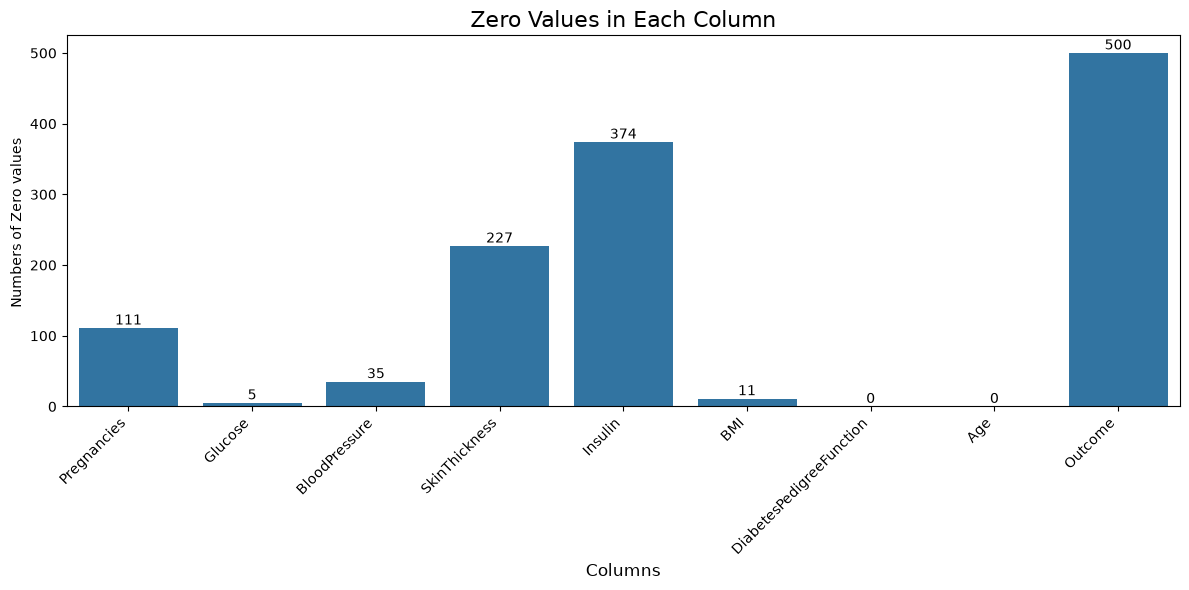

In [70]:
## Visualize zero counts in each column

import matplotlib.pyplot as plt
import seaborn as sns

# count zero values in each  column
zero_counts = (db==0).sum()

#creating the bar chart
plt.figure(figsize=(12,6))
sns.barplot(x=zero_counts.index, y=zero_counts.values)

plt.title("Zero Values in Each Column", fontsize=16)
plt.xlabel("Columns", fontsize=12)
plt.ylabel("Numbers of Zero values ")
plt.xticks(rotation=45, ha="right")

#Display the count above each bar
for i, value in enumerate(zero_counts.values):
    plt.text(i, value + 5, str(value), ha="center", fontsize=10)

plt.tight_layout()
plt.show()

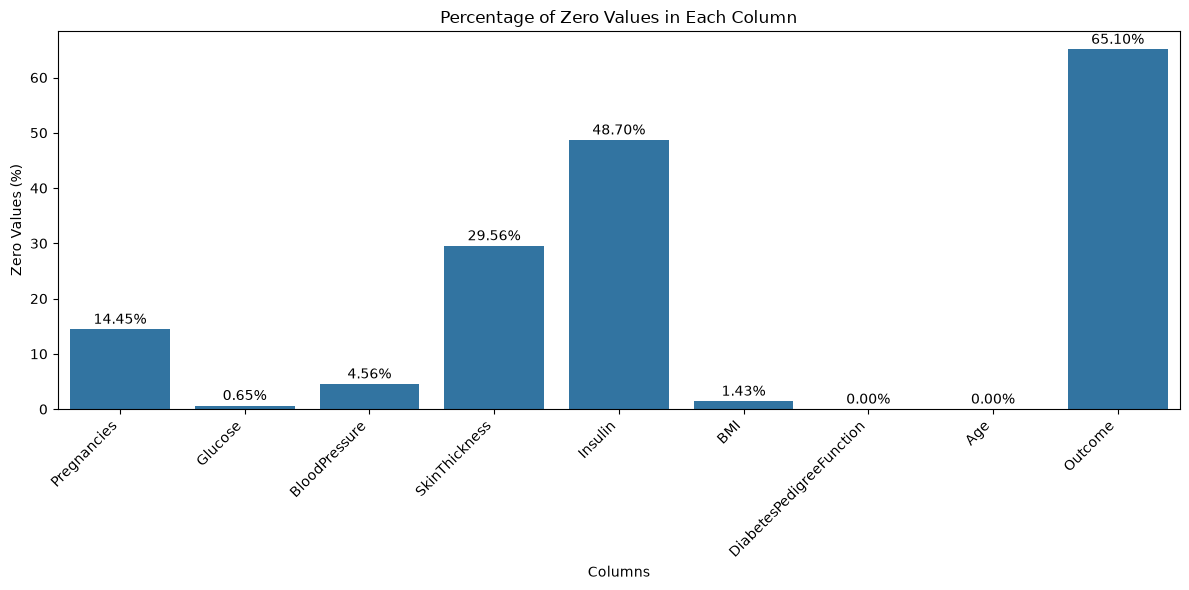

In [71]:

# Calculate zero percentages
zero_percentages = (db == 0).mean().mul(100)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=zero_percentages.index,
    y=zero_percentages.values
)

plt.title("Percentage of Zero Values in Each Column")
plt.xlabel("Columns")
plt.ylabel("Zero Values (%)")
plt.xticks(rotation=45, ha="right")

for i, value in enumerate(zero_percentages.values):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()


## 4. Data Quality Checks and Missing Values

Before training the models, I checked the dataset for data quality issues. During this stage, I examined whether any columns contained zero values that might represent missing or invalid measurements.

I noticed that zero values in some medical measurement columns, such as `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, and `BMI`, may not represent realistic measurements in this dataset. For example, a glucose level or BMI of zero would generally not be a plausible recorded measurement for a living patient.

However, I did not treat every zero as invalid. A value of zero in the `Pregnancies` column can be valid, and `Outcome = 0` is an important target label meaning that the record belongs to the non-diabetic class.

### How I Handled These Values

I replaced zero values in the selected measurement columns with `NaN` so that they could be treated as missing values during preprocessing.

I chose this approach because leaving these values unchanged could cause the model to interpret them as genuine measurements. At the same time, I recognized that I could not prove from the values alone that every zero was a data-entry error. Therefore, this cleaning decision was based on a reasonable assumption about the dataset and should be documented as a limitation.

I planned to fill the resulting missing values using median imputation rather than deleting entire records, so that I could retain more of the available training data.

In [72]:
# Replacing the inavlid zeros with missing values

import numpy as np

#create a copy of the orginal dataset
db_clean = db.copy()

# Features where zero is treated as a missing measurement
cols_with_invalid_zeros = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

# Replace zero values with NaN
db_clean[cols_with_invalid_zeros] = (
    db_clean[cols_with_invalid_zeros].replace(0, np.nan)
)

# check missing values after replacement
db_clean.isnull().sum()

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

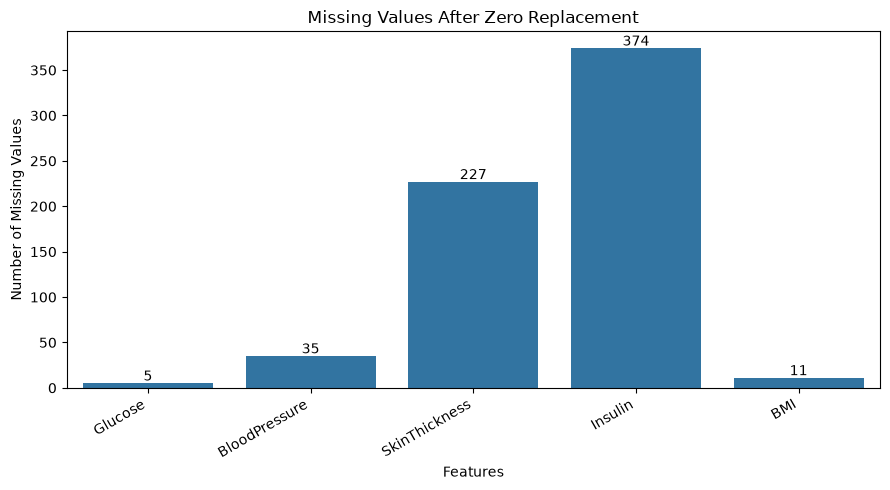

In [73]:
import matplotlib.pyplot as plt
import seaborn as sns 

missing_counts = db_clean.isnull().sum()
missing_counts = missing_counts[missing_counts > 0]

plt.figure(figsize=(9,5))

sns.barplot(
    x=missing_counts.index,
    y=missing_counts.values
)

plt.title("Missing Values After Zero Replacement")
plt.xlabel("Features")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=30, ha="right")

for i, value in enumerate(missing_counts.values):
    plt.text(i, value + 3, str(value), ha = "center")

plt.tight_layout()
plt.show()

In [74]:
# calculate medians while ignoring NaN values
db_clean[cols_with_invalid_zeros].median()

Glucose          117.0
BloodPressure     72.0
SkinThickness     29.0
Insulin          125.0
BMI               32.3
dtype: float64

In [75]:
#checking how much data is missing
missing_percentages = (
    db_clean[cols_with_invalid_zeros]
    .isnull()
    .mean()
    .mul(100)
    .round(2)
)

print(missing_percentages)

Glucose           0.65
BloodPressure     4.56
SkinThickness    29.56
Insulin          48.70
BMI               1.43
dtype: float64


## 5. Preparing the Data for Machine Learning

### Separating Features and Target

I separated the dataset into input features (`x`) and the target variable (`y`). The input features contain the measurements used by the model, while `y` contains the recorded outcome that the model attempts to predict.

### Splitting the Dataset

I divided the dataset into training and testing sets using an 80:20 split. The training set was used to train the models, while the test set was reserved for evaluating their predictions on records not used to fit the models.

I used stratified splitting to preserve approximately the same proportion of positive and negative outcome classes in both sets. I also set `random_state=42` so that I could reproduce the same split when rerunning the notebook.

### Why I Used Median Imputation

After replacing the selected zero values with missing values, I used `SimpleImputer(strategy="median")` to fill in missing feature values.

I chose the median because it is less affected by extreme values than the mean. This is useful for numerical measurements that may have skewed distributions or outliers.

I fitted the imputer using the training data and then applied it to the test data. This prevented the test data from influencing the imputation values.

### Why I Scaled Some Features

I used `StandardScaler` for algorithms such as Logistic Regression, SVM, and KNN. These algorithms can be affected by differences in the numerical scales of the input features.

Scaling puts numerical features on a more comparable scale. I included scaling in the pipelines for these algorithms so that preprocessing could be fitted correctly during model training and cross-validation.

I did not apply scaling to every algorithm because tree-based models, such as Random Forest and Decision Tree, generally do not require feature standardization.

In [76]:
# splitting the data before imputing 
from sklearn.model_selection import train_test_split

#Input features: all columns except outcome
x=db_clean.drop(columns=["Outcome"])

#Target: what the model needs to predict
y = db_clean["Outcome"]

# Split the data into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size = 0.20,
    random_state=42,
    stratify=y
)

print("Training features:", x_train.shape)
print("Testing features:", x_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (614, 8)
Testing features: (154, 8)
Training target: (614,)
Testing target: (154,)


In [77]:
from sklearn.impute import SimpleImputer
import pandas as pd

# create a median imputer
imputer = SimpleImputer(strategy="median")

#Learn medians from training data and fill its missing values
x_train_imputed = pd.DataFrame(
    imputer.fit_transform(x_train),
    columns=x_train.columns,
    index=x_train.index
)

#Fill test data using the training medians
x_test_imputed = pd.DataFrame(
    imputer.transform(x_test),
    columns=x_test.columns,
    index=x_test.index
)

print("Missing values in training features:",
     x_train_imputed.isnull().sum().sum())

print("Missing values in testing features:",
     x_test_imputed.isnull().sum().sum())


Missing values in training features: 0
Missing values in testing features: 0


## 6. Model Selection and Training

I experimented with multiple classification algorithms instead of relying on a single model. My aim was to compare their strengths and weaknesses and understand which evaluation metrics were most useful for this problem.

### Algorithms I Tested

**1. Logistic Regression**

I included Logistic Regression as a baseline classification algorithm. It is relatively simple to interpret and provides a useful starting point for understanding how well a linear decision boundary performs on the dataset.

**2. Random Forest**

I selected Random Forest because it combines predictions from multiple decision trees. It can capture nonlinear relationships and interactions between features, making it a useful candidate for tabular data.

**3. Tuned Random Forest**

After evaluating the initial Random Forest model, I used GridSearchCV to experiment with different values for the number of trees, maximum tree depth, and minimum samples per leaf. I selected recall as the tuning metric because I wanted to give particular attention to identifying positive cases.

**4. Support Vector Machine (SVM)**

I included SVM because it can separate classes using decision boundaries and can model more complex patterns through its kernel methods. I used feature scaling and class weighting in the model pipeline.

**5. K-Nearest Neighbors (KNN)**

I tested KNN to see how predictions based on nearby records compared with the other algorithms. Because KNN relies on distances between observations, I scaled the input features before training it.

**6. Decision Tree**

I included a Decision Tree because its branching structure can represent decision rules in a relatively interpretable way. I also used class weighting to account for the difference in the number of positive and negative records.

**7. Gradient Boosting**

I tested Gradient Boosting because it builds an ensemble of trees sequentially, with each stage attempting to improve on the previous model's errors.

### Why I Compared Multiple Algorithms

I did not assume that one algorithm would automatically perform best. I compared accuracy, precision, recall, and F1-score because each metric describes a different aspect of model performance.

In [78]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

#Create a pipeline: scale features, then train the model
model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

#Train the model using the training data
model.fit(x_train_imputed, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


Accuracy: 0.7078
Precision: 0.6
Recall: 0.5
F1-score: 0.5455

Classification Report:

              precision    recall  f1-score   support

           0       0.75      0.82      0.78       100
           1       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154



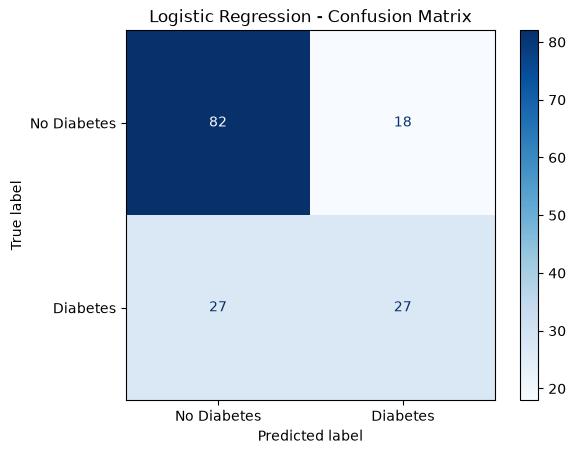

In [79]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

#Predict outcomes for the unseen test data
y_pred = model.predict(x_test_imputed)

#Calculate evaluation metrics
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1-score:", round(f1_score(y_test, y_pred), 4))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

#Visualize the confirm matrix
cm= confusion_matrix(y_test, y_pred)

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Diabetes", "Diabetes"]
)

cm_display.plot(cmap="Blues", values_format="d")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()


In [80]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Create the Random Forest pipeline
rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")), # handles missing values 
    ("classifier", RandomForestClassifier(
        n_estimators=200, # 200 decision trees
        random_state=42,
        class_weight="balanced"
    ))
])

# Train Random Forest using the original training split
rf_model.fit(x_train, y_train)

# Predict outcomes for the same test split
rf_pred = rf_model.predict(x_test)

# Evaluate Random Forest
print("Random Forest Results")
print("----------------------")
print("Accuracy:", round(accuracy_score(y_test, rf_pred), 4))
print("Precision:", round(precision_score(y_test, rf_pred), 4))
print("Recall:", round(recall_score(y_test, rf_pred), 4))
print("F1-score:", round(f1_score(y_test, rf_pred), 4))

Random Forest Results
----------------------
Accuracy: 0.7403
Precision: 0.6167
Recall: 0.6852
F1-score: 0.6491


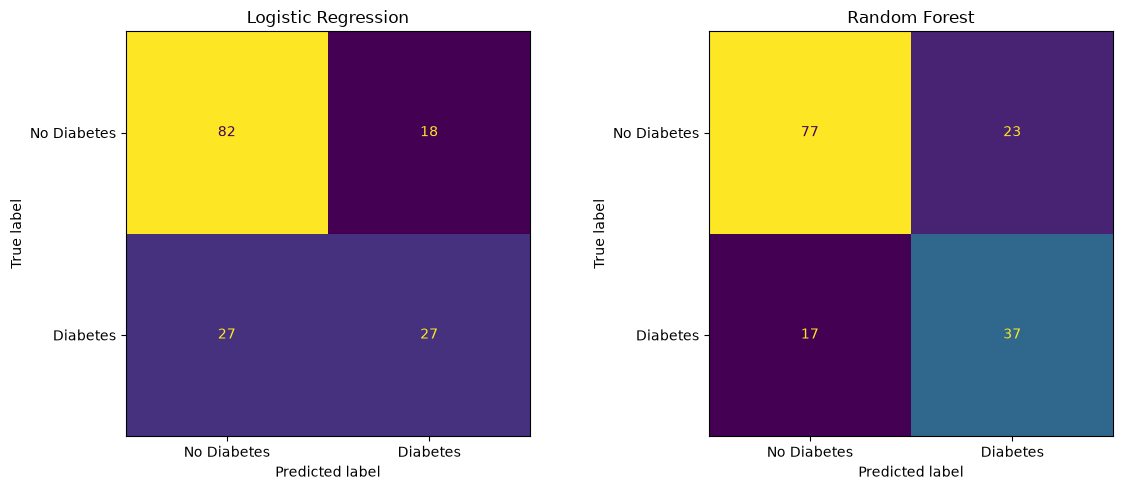

In [81]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Logistic Regression confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No Diabetes", "Diabetes"],
    values_format="d",
    ax=axes[0],
    colorbar=False
)
axes[0].set_title("Logistic Regression")

# Random Forest confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_pred,
    display_labels=["No Diabetes", "Diabetes"],
    values_format="d",
    ax=axes[1],
    colorbar=False
)
axes[1].set_title("Random Forest")

plt.tight_layout()
plt.show()


## 7. Hyperparameter Tuning with GridSearchCV

After training the initial models, I tuned the Random Forest model using GridSearchCV.

I tested different combinations of `n_estimators`, `max_depth`, and `min_samples_leaf`. I used stratified five-fold cross-validation to evaluate the parameter combinations while maintaining the approximate class distribution in each fold.

I selected recall as the scoring metric for tuning. This meant that the search prioritized identifying positive cases rather than maximizing accuracy alone.

The best parameter combination returned by my search was:

- `n_estimators = 200`
- `max_depth = 5`
- `min_samples_leaf = 4`

The best cross-validation recall reported by GridSearchCV was approximately 0.771.

These parameters were selected based on the search results. They do not guarantee that the model will perform equally well on every new dataset.

In [82]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# preprocessing inside this pipeline
rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        random_state=42,
        class_weight="balanced"
    ))
])

# Settings we want to compare
param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4]
}

# Preserve class proportions across the 5 validation folds
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Search for the best settings using training data only
grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring="recall",
    cv=cv,
    n_jobs=-1,
    refit=True
)

grid_search.fit(x_train, y_train)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation recall:")
print(round(grid_search.best_score_, 4))


Best parameters:
{'classifier__max_depth': 5, 'classifier__min_samples_leaf': 4, 'classifier__n_estimators': 200}

Best cross-validation recall:
0.771


Tuned Random Forest - Test Results
-----------------------------------
Accuracy: 0.7468
Precision: 0.6087
Recall: 0.7778
F1-score: 0.6829


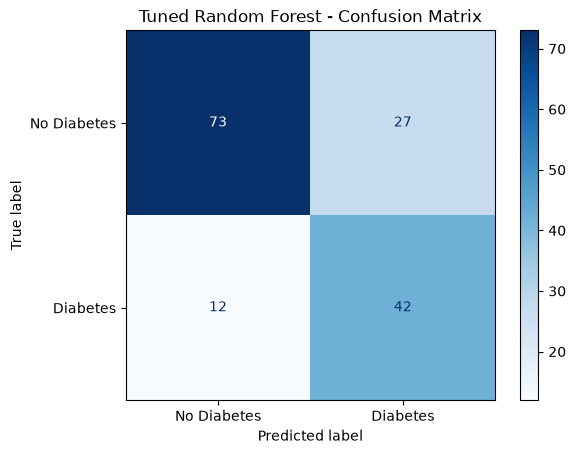

In [83]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Get the best model selected by GridSearchCV
best_rf_model = grid_search.best_estimator_

# Predict on the reserved test data
tuned_pred = best_rf_model.predict(x_test)

# Calculate test metrics
print("Tuned Random Forest - Test Results")
print("-----------------------------------")
print("Accuracy:", round(accuracy_score(y_test, tuned_pred), 4))
print("Precision:", round(precision_score(y_test, tuned_pred), 4))
print("Recall:", round(recall_score(y_test, tuned_pred), 4))
print("F1-score:", round(f1_score(y_test, tuned_pred), 4))

# Plot the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    tuned_pred,
    display_labels=["No Diabetes", "Diabetes"],
    values_format="d",
    cmap="Blues"
)

plt.title("Tuned Random Forest - Confusion Matrix")
plt.show()


In [84]:
# Comparing Additional Models


from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Define the four additional models
models = {
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(class_weight="balanced"))
    ]),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=5))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        random_state=42
    )
}

# Train and evaluate each model
results = []

for name, model_to_test in models.items():
    model_to_test.fit(x_train_imputed, y_train)

    predictions = model_to_test.predict(x_test_imputed)

    results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, predictions), 4),
        "Precision": round(precision_score(
            y_test, predictions, zero_division=0
        ), 4),
        "Recall": round(recall_score(
            y_test, predictions, zero_division=0
        ), 4),
        "F1-score": round(f1_score(
            y_test, predictions, zero_division=0
        ), 4)
    })

# Display results from best to worst F1-score
import pandas as pd

results_db = pd.DataFrame(results)
results_db = results_db.sort_values(
    by="F1-score", ascending=False
).reset_index(drop=True)

results_db


,Model,Accuracy,Precision,Recall,F1-score
0,SVM,0.7273,0.5909,0.7222,0.6500
1,KNN,0.7532,0.6600,0.6111,0.6346
2,Gradient Boosting,0.7532,0.6818,0.5556,0.6122
3,Decision Tree,0.7143,0.6190,0.4815,0.5417


In [85]:

comparison_db = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": 0.7078,
        "Precision": 0.6000,
        "Recall": 0.5000,
        "F1-score": 0.5455
    },
    {
        "Model": "Random Forest",
        "Accuracy": 0.7403,
        "Precision": 0.6167,
        "Recall": 0.6852,
        "F1-score": 0.6491
    },
    {
        "Model": "Tuned Random Forest",
        "Accuracy": 0.7468,
        "Precision": 0.6087,
        "Recall": 0.7778,
        "F1-score": 0.6829
    },
    {
        "Model": "SVM",
        "Accuracy": 0.7273,
        "Precision": 0.5909,
        "Recall": 0.7222,
        "F1-score": 0.6500
    },
    {
        "Model": "KNN",
        "Accuracy": 0.7532,
        "Precision": 0.6600,
        "Recall": 0.6111,
        "F1-score": 0.6346
    },
    {
        "Model": "Gradient Boosting",
        "Accuracy": 0.7532,
        "Precision": 0.6818,
        "Recall": 0.5556,
        "F1-score": 0.6122
    },
    {
        "Model": "Decision Tree",
        "Accuracy": 0.7143,
        "Precision": 0.6190,
        "Recall": 0.4815,
        "F1-score": 0.5417
    }
])

comparison_db.sort_values(
    by="F1-score", ascending=False
).reset_index(drop=True)


,Model,Accuracy,Precision,Recall,F1-score
0,Tuned Random Forest,0.7468,0.6087,0.7778,0.6829
1,SVM,0.7273,0.5909,0.7222,0.6500
2,Random Forest,0.7403,0.6167,0.6852,0.6491
3,KNN,0.7532,0.6600,0.6111,0.6346
4,Gradient Boosting,0.7532,0.6818,0.5556,0.6122
5,Logistic Regression,0.7078,0.6000,0.5000,0.5455
6,Decision Tree,0.7143,0.6190,0.4815,0.5417


## 8. Model Evaluation and Comparison

I evaluated the models using accuracy, precision, recall, and F1-score. I also used stratified five-fold cross-validation to compare their average performance across different training and validation folds.

### Understanding the Evaluation Metrics

- **Accuracy:** The proportion of all predictions that were correct.
- **Precision:** The proportion of predicted positive cases that were actually positive in the recorded labels.
- **Recall:** The proportion of actual positive cases that the model correctly identified.
- **F1-score:** The harmonic mean of precision and recall.

I paid particular attention to recall because missing positive cases is an important concern in a health-related classification task. However, precision also matters because false-positive predictions can lead to unnecessary concern and follow-up.

In [86]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
import pandas as pd

## cross validation
cv_models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=1000, random_state=42))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Tuned Random Forest": best_rf_model,

    "SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", SVC(class_weight="balanced"))
    ]),

    "KNN": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=5))
    ]),

    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", DecisionTreeClassifier(
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", GradientBoostingClassifier(
            n_estimators=100,
            random_state=42
        ))
    ])
}

In [87]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

cv_results = []

for name, model in cv_models.items():
    scores = cross_validate(
        model,
        x_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1-score": scores["test_f1"].mean()
    })

cv_db = pd.DataFrame(cv_results)

metric_columns = ["Accuracy", "Precision", "Recall", "F1-score"]
cv_db[metric_columns] = cv_db[metric_columns].round(4)

cv_db.sort_values(
    by="F1-score",
    ascending=False
).reset_index(drop=True)

,Model,Accuracy,Precision,Recall,F1-score
0,Tuned Random Forest,0.7655,0.6364,0.7710,0.6967
1,SVM,0.7605,0.6372,0.7617,0.6902
2,Random Forest,0.7622,0.6530,0.6868,0.6688
3,Logistic Regression,0.7882,0.7638,0.5748,0.6545
4,Gradient Boosting,0.7557,0.6721,0.5981,0.6308
5,KNN,0.7296,0.6367,0.5654,0.5939
6,Decision Tree,0.6727,0.5324,0.5329,0.5323


### What I Observed

In my cross-validation comparison, Tuned Random Forest achieved the highest average F1-score of approximately 0.6967 and recall of approximately 0.7710 among the models I tested.

SVM performed closely, with an average F1-score of approximately 0.6902 and recall of approximately 0.7617. Logistic Regression achieved the highest average accuracy in my comparison, but its recall was lower.

These results showed me that the model with the highest accuracy is not necessarily the best choice when I also want to identify positive cases. Based on the metrics I prioritized, I selected Tuned Random Forest as my current candidate model.

The tuned model was selected using cross-validation, so its reported cross-validation performance may be optimistic. A nested cross-validation procedure would provide a more rigorous estimate after hyperparameter tuning.

Final Test Results — Tuned Random Forest
------------------------------------------
Accuracy : 0.7468
Precision: 0.6087
Recall   : 0.7778
F1-score : 0.6829

Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.86      0.73      0.79       100
    Diabetes       0.61      0.78      0.68        54

    accuracy                           0.75       154
   macro avg       0.73      0.75      0.74       154
weighted avg       0.77      0.75      0.75       154



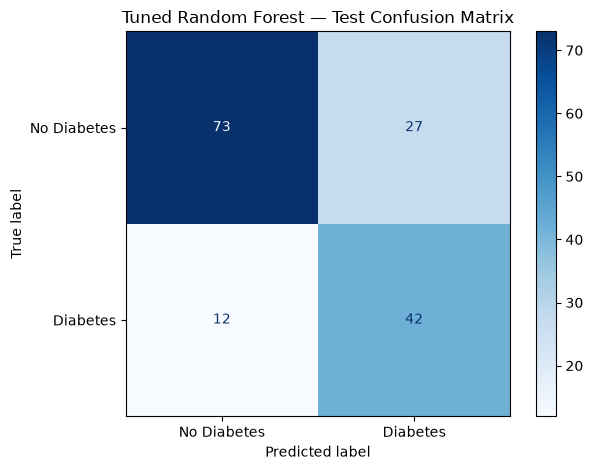

In [88]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict on the held-out test data
final_predictions = best_rf_model.predict(x_test)

# Calculate evaluation metrics
print("Final Test Results — Tuned Random Forest")
print("-" * 42)
print("Accuracy :", round(accuracy_score(y_test, final_predictions), 4))
print("Precision:", round(precision_score(y_test, final_predictions), 4))
print("Recall   :", round(recall_score(y_test, final_predictions), 4))
print("F1-score :", round(f1_score(y_test, final_predictions), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    final_predictions,
    target_names=["No Diabetes", "Diabetes"],
    zero_division=0
))

# Plot the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_predictions,
    display_labels=["No Diabetes", "Diabetes"],
    cmap="Blues"
)

plt.title("Tuned Random Forest — Test Confusion Matrix")
plt.tight_layout()
plt.show()

### Test Set Evaluation

I evaluated the selected Tuned Random Forest model on the held-out test set containing 154 records.

The model achieved the following results:

- Accuracy: 0.7468
- Precision: 0.6087
- Recall: 0.7778
- F1-score: 0.6829

The confusion matrix showed 73 true negatives, 42 true positives, 27 false positives, and 12 false negatives.

The model identified 42 of the 54 records with a positive outcome, while missing 12 positive cases. It also predicted a positive outcome for 27 records whose actual label was negative.

These results helped me understand the trade-off between identifying more positive cases and making incorrect positive predictions.

I had already examined the test-set results while comparing models during development, so the test set was not completely untouched during model selection. For a stricter final evaluation, I would reserve a fresh test set or use nested cross-validation to reduce selection bias.

## 9. Saving and Testing the Trained Model

After evaluating the models, I saved the selected Random Forest pipeline using `joblib`. The saved pipeline includes the fitted median imputer and the trained classifier, allowing me to reuse the model without training it from scratch each time.

I then loaded the saved file and passed one record from the test dataset to the model to verify that it could generate a prediction.

The example returned `Diabetes`, corresponding to a predicted class of `1`. This confirmed that I could load the saved pipeline and run the prediction code successfully.

This was a technical verification of the saved model, not a confirmation of an individual's medical condition.

In [89]:
import joblib

# Saving the complete trained pipeline
joblib.dump(best_rf_model, "diabetes_prediction_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [90]:
loaded_model = joblib.load("diabetes_prediction_model.pkl")

# Select one test record
sample = x_test.iloc[[0]]

# Make a prediction
prediction = loaded_model.predict(sample)[0]

if prediction == 1:
    print("Model prediction: Diabetes")
else:
    print("Model prediction: No Diabetes")

Model prediction: Diabetes


## 10. Conclusion and Future Improvements

Through this project, I worked through the main stages of a machine learning classification workflow, including data exploration, preprocessing, model training, hyperparameter tuning, cross-validation, evaluation, and model persistence.

I learned that data quality decisions are important because invalid values can affect model training. I also learned why preprocessing should be fitted using training data and why pipelines are useful for preventing information leakage during cross-validation.

Among the models I compared, Tuned Random Forest achieved the highest average F1-score and recall in my reported cross-validation results. On the held-out test set, it achieved an F1-score of 0.6829 and recall of 0.7778.

However, the model still produced false-positive and false-negative predictions. Its performance should therefore not be interpreted as sufficient for real-world medical use.

### Limitations

- The model was trained on a limited dataset and may not generalize to different populations.
- Replacing zero measurements with missing values was an assumption based on the dataset's characteristics.
- The test results were examined during model selection, which may introduce selection bias.
- The model has not undergone clinical validation and should not be used to diagnose diabetes.

### Future Improvements

If I continue developing this project, I would explore threshold tuning, more rigorous nested cross-validation, additional model evaluation methods, and validation on an independent dataset. I would also improve the project documentation and build a simple interface to demonstrate the saved model.

Overall, this project helped me understand how to move from raw data to a trained, evaluated, and reusable machine learning model, while recognizing the importance of careful evaluation and responsible interpretation.